# Module 03: Assignment for 1-D Diffusion Problem - Thawing Permafrost

### 1. Introduction and Background

In this notebook you are going to investigate the impact of three climate change scenarios on our previously developed model of the vertical distribution of temperature in a permafrost soil. 


Again, the equation for 1-dimensional heat diffusion into a soil is presented below:
$$
\rho_s \cdot C_s \cdot \frac{\partial T_s}{\partial t} = \frac{\partial T_s}{\partial z}\left(k_s \cdot \frac{\partial T_s}{\partial z}\right)
$$

where $\rho_s$ (kg/m^3) is the bulk density of the soil, $C_s$ (J/(kg K)) is the heat capacity of the soil, $k_s$ (W/(m K)) is the thermal conductivity of the soil, $T_s$ is the temperature of the soil at some time $t$ and depth in the soil $z$. For the sake of simplicity, we're going to assume that the thermal conductivity is constant. This assumption is not strictly true, as $k_s$ changes with the amount and phase (frozen or liquid) of water in the soil. But it makes the math much simpler and is good starting point for a toy model. Under this assumption we can simplify the above equation to,

$$
\rho_s \cdot C_s \cdot \frac{\partial T_s}{\partial t} = k_s \frac{\partial T_s^2}{\partial^2 z}
$$

Going further, if we also assume that the bulk density ($rho_s$) and heat capacity ($C_s$) are constant, then we can combine them with the thermal conductivity and reduce them to a single parameter that is often referred to as the _thermal diffusivity_ ($D_s$) and has dimensions of m^2/s, 

$$
D_s = \frac{k_s}{\rho_s \cdot C_s}
$$

Substituting into the above, we obtain the following governing equation that our model will solve, 

$$
\frac{\partial T_s}{\partial t} = D_s \frac{\partial T_s^2}{\partial^2 z}
$$

Your __top boundary condition__, we will assume sinusoidal forcing of air temperature superimposed on a linear trend in mean annual temperatures at the surface, with a period of one year. In this notebook we will explore three scenarios. Scenario 1 is a linear increase in mean annual temperature at a rate that results in 1.5 °C of warming by 2100. Scenario 2 is a linear increase in mean annual temperature at a rate that results in 3.0 °C of warming by 2100. Scenario 3 is a linear increase in mean annual temperature at a rate that results in 4.5 °C of warming by 2100. We will start all simulations in 2020. 

Your __bottom boundary condition__, we will assume a constant temperature at the initial mean annual air temperature. 

Yur __initial condition__ will be a constant temperature (isothermal) at the mean annual air temperature. If interested you can copy this notebook and modify these values.

### 2. Initial Setup

Below, we set the values for our spatial domain, simulation period, soil properties, and boundary conditions. 

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Soil column properties
zs = 500.0 # Depth of soil [cm]
dz = 15.0   # Numerical model layer thickness [cm]

# Soil properties (obtained from https://doi.org/10.1029/2017JF004535)
Cs = 635.0 # Heat capacity of soil/permafrost [J/(kg K)]
ks = 0.25  # Thermal conductivity of soil/permafrost [W/(m K)]
rhos = 920.0 # Bulk density of permafrost [kg/m^3] 

dt = 0.25 # Time step [day]

#### 2.1 Load and Plot the Air Temperature Trends

In [28]:
data = np.loadtxt('PermafrostTemperatureScenarios.csv', delimiter=',', skiprows=1)

t_year = data[:,0]
T_15 = data[:,1]
T_30 = data[:,2]
T_45 = data[:,3]

Text(0, 0.5, 'Annual average air temperature [°C]')

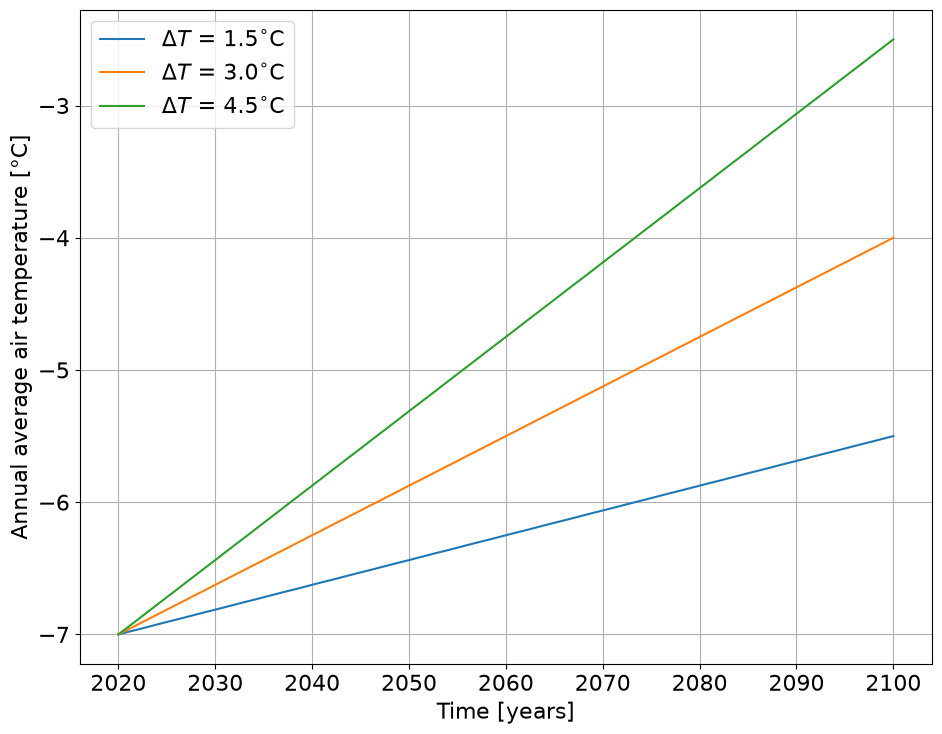

In [29]:
## change the font size for all of our plots to be more legible
plt.rcParams.update({'font.size': 16})

plt.figure(figsize=(11.0,8.5))
plt.plot(t_year,T_15,label=r'$\Delta T$ = 1.5${}^{\circ}$C')
plt.plot(t_year,T_30,label=r'$\Delta T$ = 3.0${}^{\circ}$C')
plt.plot(t_year,T_45,label=r'$\Delta T$ = 4.5${}^{\circ}$C')
plt.legend(loc='upper left')
plt.grid()
plt.xlabel('Time [years]')
plt.ylabel('Annual average air temperature [°C]')

#### 2.2 Setup the Simulation Time Period

In [30]:
# Time properties of simulation
t0 = t_year[0]
tf = t_year[-1]

t = np.arange(t0,tf+(dt/365),(dt/365))
Nt = t.size
print('The number of time steps: Nt = ',str(Nt))

The number of time steps: Nt =  116801


### 3. Setup Boundary Conditions

In [31]:
# Boundary conditions
Ttopamp = 35.0
Tbottom = -7.0

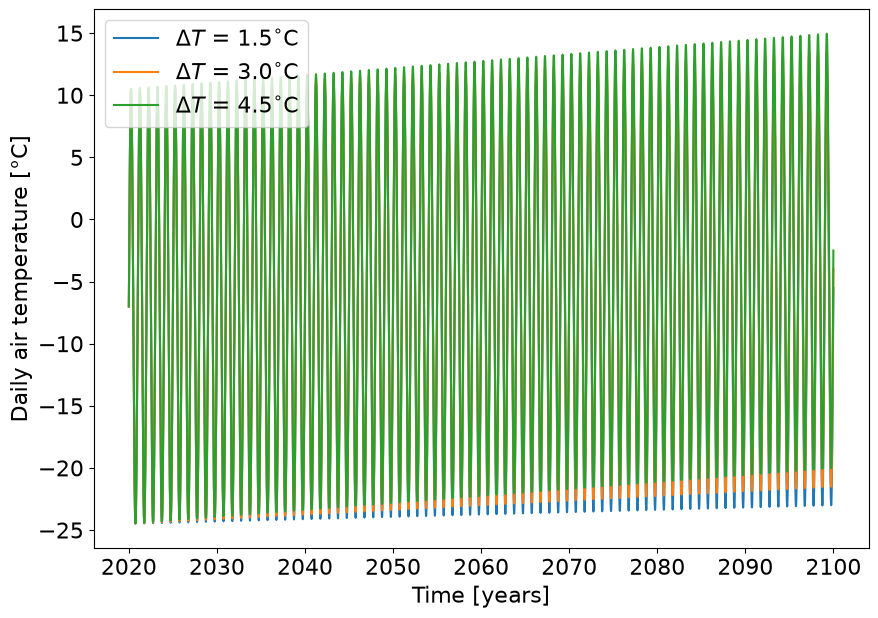

In [32]:
Ttop_15 = np.interp(t, t_year, T_15) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t) #convert annual average temperature to daily temperature with a sinusoidal function for1.5°C scenario
Ttop_30 = np.interp(t, t_year, T_30) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t) #convert annual average temperature to daily temperature with a sinusoidal function for3.0°C scenario
Ttop_45 = np.interp(t, t_year, T_45) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t) #convert annual average temperature to daily temperature with a sinusoidal function for4.5°C scenario

#create figure to show the daily air temperature for each scenario
plt.figure(figsize=(10.0,7.0))
plt.plot(t, Ttop_15, label=r'$\Delta T$ = 1.5${}^{\circ}$C')
plt.plot(t, Ttop_30, label=r'$\Delta T$ = 3.0${}^{\circ}$C')
plt.plot(t, Ttop_45, label=r'$\Delta T$ = 4.5${}^{\circ}$C')
plt.xlabel('Time [years]')
plt.ylabel('Daily air temperature [°C]')
plt.legend(loc='upper left')
plt.show()

### 4. Setup Spatial Domain

In [33]:
#using the same as the implicit example 
z = np.arange(dz/2, zs, dz)
Nz = z.size
print('Here are the locations of our cells: z = \n' + str(z))
print('The number of cells is: Nz = ',str(Nz))

Here are the locations of our cells: z = 
[  7.5  22.5  37.5  52.5  67.5  82.5  97.5 112.5 127.5 142.5 157.5 172.5
 187.5 202.5 217.5 232.5 247.5 262.5 277.5 292.5 307.5 322.5 337.5 352.5
 367.5 382.5 397.5 412.5 427.5 442.5 457.5 472.5 487.5]
The number of cells is: Nz =  33


### 5. Setup Initial Condition

In [34]:
#create Ts = 0 for if true condition in step 8
Ts0 = Tbottom*np.ones((Nz,1))


### 6. Calculate $D$, $\mathbf{A}$, and $\mathbf{B}$ Matrices for Implicit or Crank-Nicolson Method

In [35]:
#calculating D from implicit example
Ds = ks / (rhos * Cs)
print('Soil diffusivity = '+str(Ds)+' m^2/s')

# Convert alpha to units consistent with domain [cm^2/day]
Ds = Ds*(100.0**2)*(24.0*3600.0)
print('Soil diffusivity = '+str(Ds)+' cm^2/day')

alpha = Ds*dt/(dz**2)
print('Diffusion number '+str(alpha))


#calculating A
Delta2 = np.diag(-2.0*np.ones((Nz))) + np.diag(np.ones((Nz-1)),1) + np.diag(np.ones((Nz-1)),-1) #creates matrix below with middle and upper and lower diagonals filled with -2 and 1's respectively
print(Delta2)

I = np.eye(Nz)
A = I - alpha*Delta2
A[0,:] = np.hstack((1.0,np.zeros((Nz-1)))) #set our top boundary condition
A[-1,:] = np.hstack((np.zeros((Nz-1)),1.0)) #set our bottom boundary condition
print(A)

#calculating B


Soil diffusivity = 4.279356384799726e-07 m^2/s
Soil diffusivity = 369.7363916466963 cm^2/day
Diffusion number 0.41081821294077364
[[-2.  1.  0. ...  0.  0.  0.]
 [ 1. -2.  1. ...  0.  0.  0.]
 [ 0.  1. -2. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ... -2.  1.  0.]
 [ 0.  0.  0. ...  1. -2.  1.]
 [ 0.  0.  0. ...  0.  1. -2.]]
[[ 1.          0.          0.         ...  0.          0.
   0.        ]
 [-0.41081821  1.82163643 -0.41081821 ...  0.          0.
   0.        ]
 [ 0.         -0.41081821  1.82163643 ...  0.          0.
   0.        ]
 ...
 [ 0.          0.          0.         ...  1.82163643 -0.41081821
   0.        ]
 [ 0.          0.          0.         ... -0.41081821  1.82163643
  -0.41081821]
 [ 0.          0.          0.         ...  0.          0.
   1.        ]]


### 7. Preallocate Storage for Soil Temperatures

In [36]:
Ts = np.zeros((Nz,Nt))

### 8. Apply Solution And Compute Temperatures

In [37]:
#Do something similar to mod 2 and use a user defined function to calculate temp over time for any senario and then apply it to each of the three scenarios.

A_inv = np.linalg.inv(A)  # still computed once, outside the function

def run_diffusion_model(Ttop, Ts0, A_inv, Tbottom, Nt):
    """Runs the soil temperature diffusion model for a given surface temperature scenario."""
    Nz = Ts0.size
    Ts = np.zeros((Nz, Nt))

    for i in np.arange(Nt):
        if i == 0:
            Tsi = np.squeeze(Ts0).copy()  # initial condition for the first time step
        else:
            Tsi = Ts[:, i-1].copy()       # previous time step's solution
            Tsi[0] = Ttop[i]              # top boundary condition
            Tsi[-1] = Tbottom             # bottom boundary condition

        Tsip1 = np.matmul(A_inv, Tsi)     # next time step
        Ts[:, i] = np.squeeze(Tsip1)      # store the solution

    return Ts

scenarios = {
    '1.5°C': Ttop_15,
    '3.0°C': Ttop_30,
    '4.5°C': Ttop_45
}

results = {}
for name, Ttop_scenario in scenarios.items():
    results[name] = run_diffusion_model(Ttop_scenario, Ts0, A_inv, Tbottom, Nt)

Ts_15 = results['1.5°C']
Ts_30 = results['3.0°C']
Ts_45 = results['4.5°C']

### 9. Plot Results, Analyze, and Interpret

Create plots of the following:

1. A plot of 3 x 2 subplots of the vertical temperature distribution with time. Each row should correspond to each of the 3 climate change scenarios wiht the top row being the $\Delta T$ = 1.5 ${}^{\circ}$ C, the middle being $\Delta T$ = 3.0 ${}^{\circ}$ C , and the bottom row being $\Delta T$ = 4.5 ${}^{\circ}$ C. The left column should correspond to the ___first___ 10 years of simulation, and the right column the ___last___ 10 years of simulation.
2. A plot of 2 x 2 subplots of the temperature at four different levels. One subplot of temperature versus time for all three scenarios at a depth of 50 cm, the second subplot the same information at 100 cm, the third subplot the same information at 200 cm, and the fourth subplot the same information at 400 cm. 
3. A markdown table showing the approximate depth of the active layer for each scenario for the first, a middle, and the final decade of the simulation.  

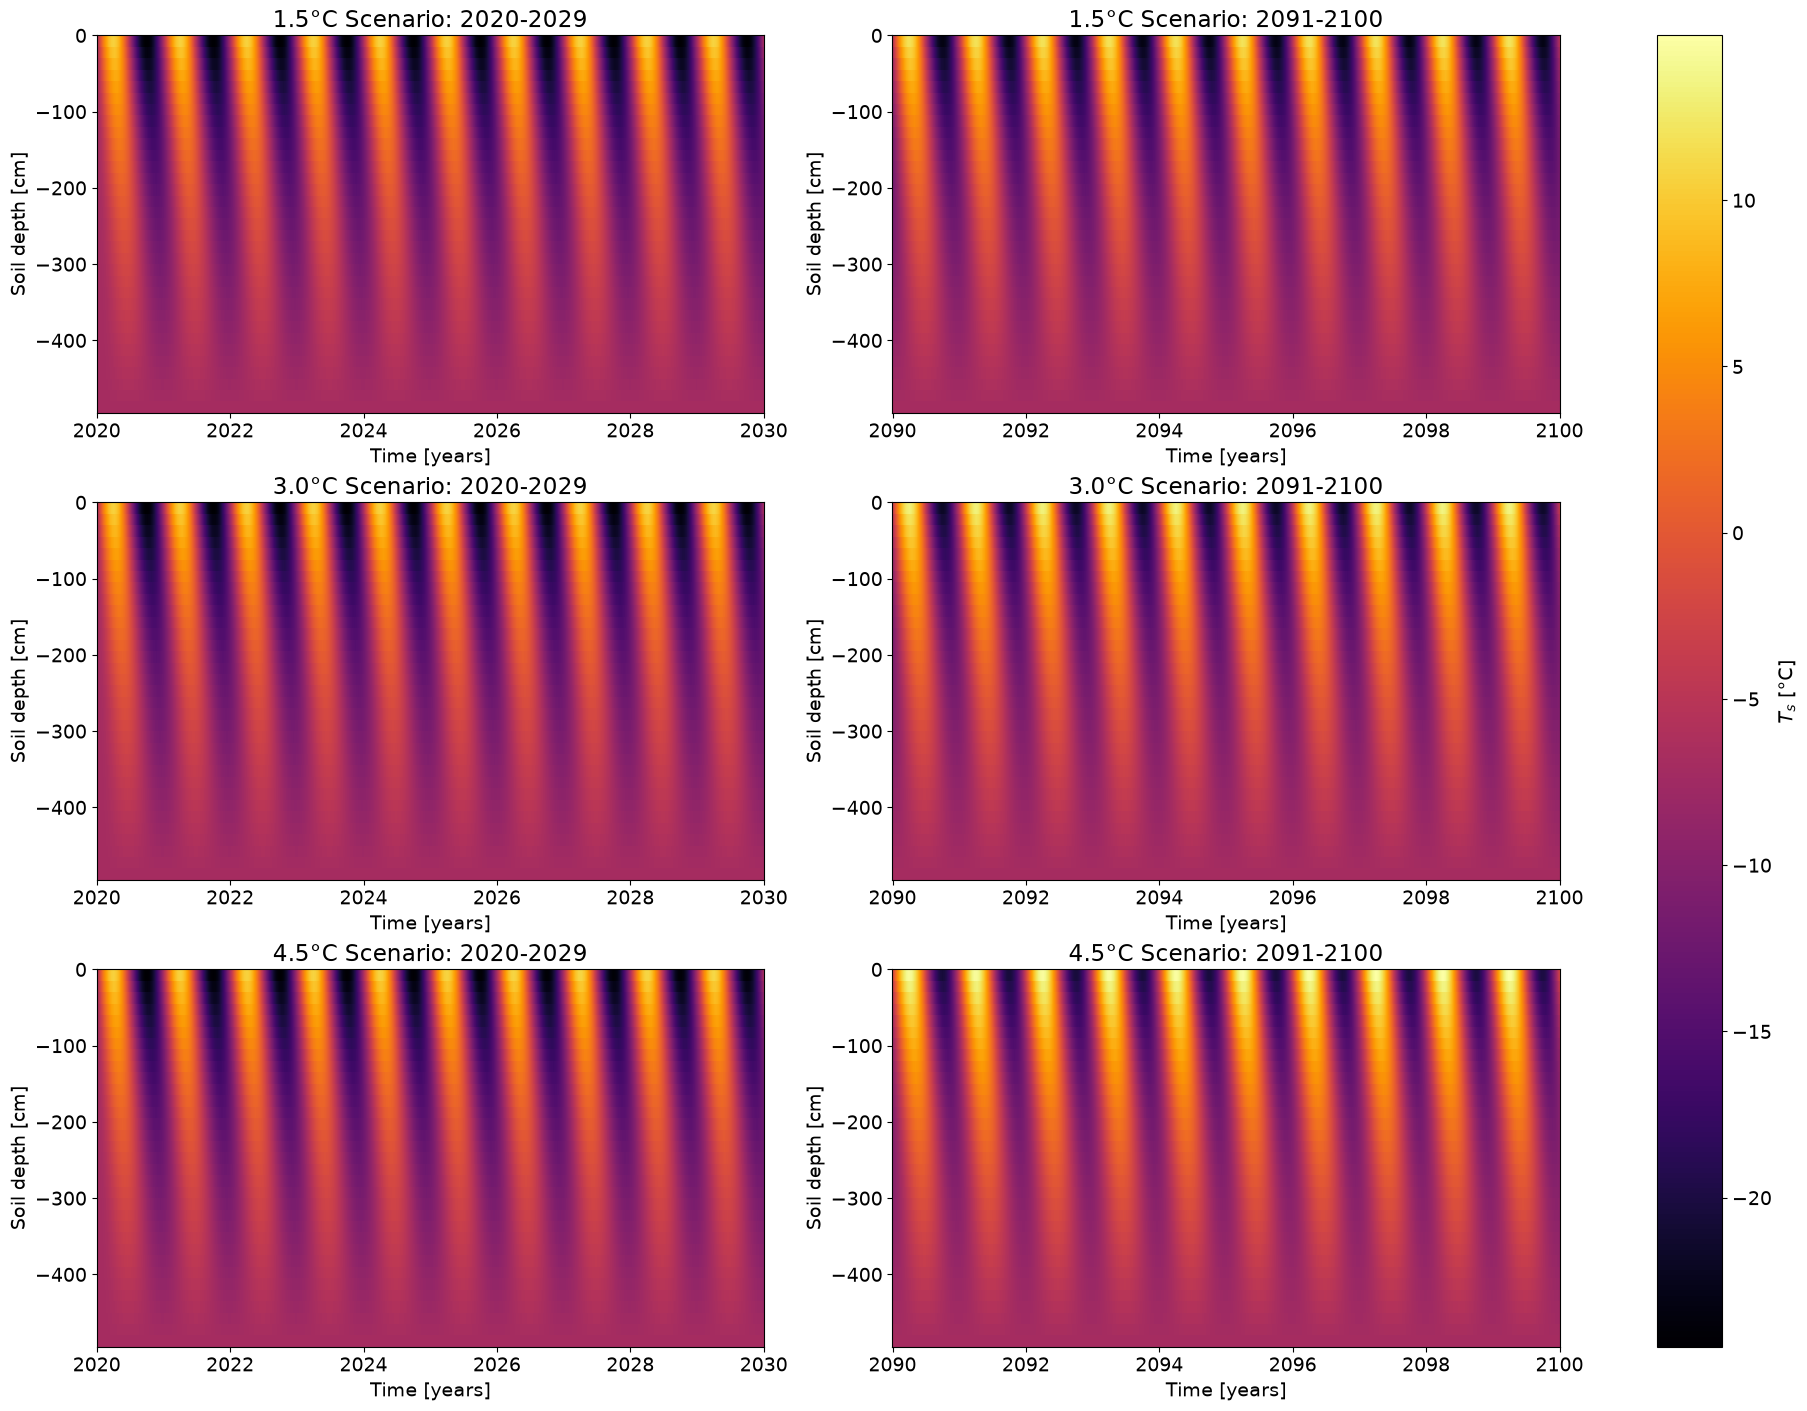

In [38]:
plt.rcParams.update({'font.size': 14})  # slightly smaller than 16 so six panels don't feel crowded

scenario_Ts = {
    '1.5°C': Ts_15,
    '3.0°C': Ts_30,
    '4.5°C': Ts_45
}

# Boolean masks selecting the first and last 10 years of the time array
first_mask = t <= t[0] + 10
last_mask  = t >= t[-1] - 10
windows = [(first_mask, '2020-2029'), (last_mask, '2091-2100')]

# Shared color limits so colors mean the same temperature in every panel
vmin = min(Ts_scn.min() for Ts_scn in scenario_Ts.values())
vmax = max(Ts_scn.max() for Ts_scn in scenario_Ts.values())

fig, axes = plt.subplots(3, 2, figsize=(18, 14), constrained_layout=True)

for row, (name, Ts_scn) in enumerate(scenario_Ts.items()):
    for col, (mask, window_label) in enumerate(windows):
        ax = axes[row, col]
        mesh = ax.pcolormesh(t[mask], -z, Ts_scn[:, mask],
                             cmap='inferno', vmin=vmin, vmax=vmax, shading='auto')
        ax.set_title(f'{name} Scenario: {window_label}')
        ax.set_xlabel('Time [years]')
        ax.set_ylabel('Soil depth [cm]')

fig.colorbar(mesh, ax=axes, label='$T_s$ [°C]')  # one colorbar shared by all six panels
plt.show()

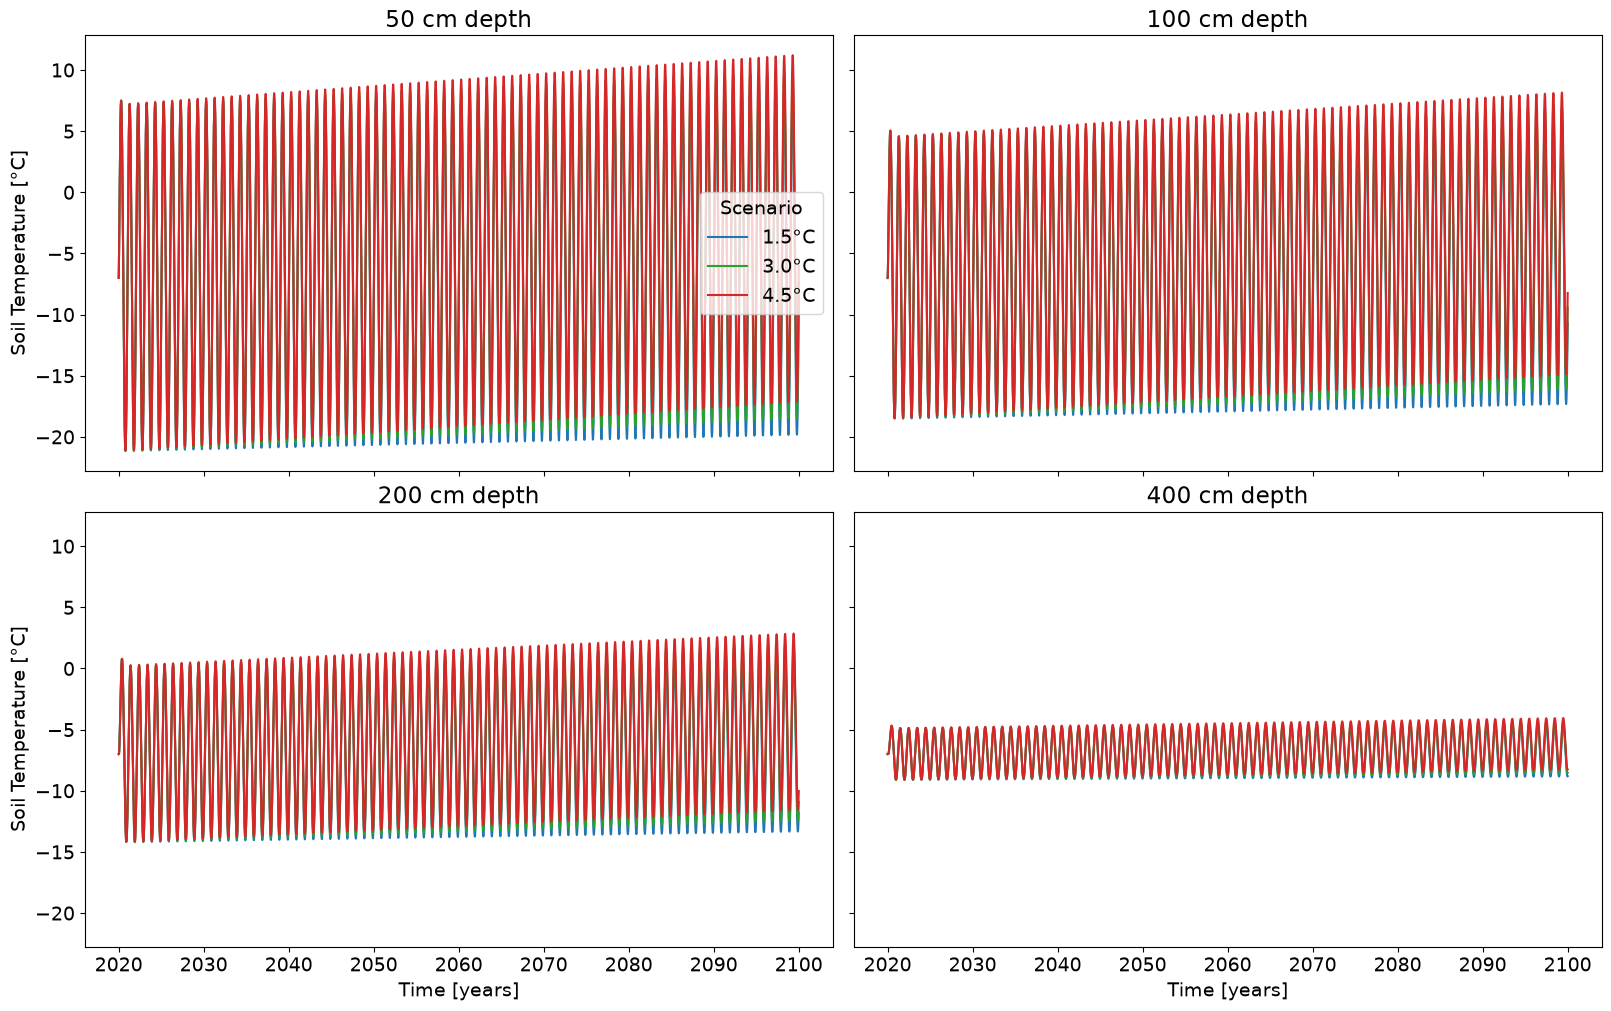

In [39]:
#showing temperature in each scenario at specific depths (rounded to the nearest cell)
plt.rcParams.update({'font.size': 14})

target_depths = [50.0, 100.0, 200.0, 400.0]
iz_list = [(np.absolute(z - d)).argmin() for d in target_depths]

scenario_colors = {'1.5°C': 'tab:blue', '3.0°C': 'tab:green', '4.5°C': 'tab:red'}

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True, constrained_layout=True)

for ax, target, iz in zip(axes.flat, target_depths, iz_list):
    for name, Ts_scn in scenario_Ts.items():
        ax.plot(t, Ts_scn[iz, :], color=scenario_colors[name], label=name)
    ax.set_title(f'{target:.0f} cm depth')

for ax in axes[1, :]:
    ax.set_xlabel('Time [years]')
for ax in axes[:, 0]:
    ax.set_ylabel('Soil Temperature [°C]')

axes[0, 0].legend(title='Scenario')
plt.show()

In [40]:
#find active layer for each scenario for the specified decades 
def active_layer_depth(Ts_scn, t, z, years):
    """Deepest cell center (cm) that is above 0°C at any point during each calendar year."""
    z1d = np.squeeze(z)
    year_of_step = np.floor(t + 1e-9).astype(int)  # tiny offset guards against float error at year boundaries
    depths = []
    for yr in years:
        in_year = year_of_step == yr
        if not in_year.any():
            raise ValueError(f'No time steps found for {yr}; check that t is in calendar years')
        thawed_ever = (Ts_scn[:, in_year] > 0).any(axis=1)  # was each cell above 0°C at some point this year?
        depths.append(z1d[thawed_ever].max() if thawed_ever.any() else 0.0)  # 0 if the whole column stayed frozen
    return np.array(depths)

decades = {
    '2020–2029': range(2020, 2030),
    '2055–2065': range(2055, 2065),
    '2091–2100': range(2090, 2100),
}
scen_names = list(scenario_Ts.keys())

depth_table = {
    label: {name: active_layer_depth(Ts_scn, t, z, yrs) for name, Ts_scn in scenario_Ts.items()}
    for label, yrs in decades.items()
}

cols = []
for label in decades:
    cols += [label, *scen_names]

lines = ['| ' + ' | '.join(cols) + ' |',
         '|' + '---|' * len(cols)]

n_rows = max(len(yrs) for yrs in decades.values())
for r in range(n_rows):
    row = []
    for label, yrs in decades.items():
        yrs = list(yrs)
        if r < len(yrs):
            row += [str(yrs[r])] + [f'{depth_table[label][name][r]:.1f}' for name in scen_names]
        else:
            row += [''] * (1 + len(scen_names))  # blank padding if a decade is shorter
    lines.append('| ' + ' | '.join(row) + ' |')

table_md = '\n'.join(lines)
print(table_md)  # copy this output into a markdown cell

from IPython.display import Markdown, display
display(Markdown(table_md))  # preview how it renders

| 2020–2029 | 1.5°C | 3.0°C | 4.5°C | 2055–2065 | 1.5°C | 3.0°C | 4.5°C | 2091–2100 | 1.5°C | 3.0°C | 4.5°C |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2020 | 217.5 | 217.5 | 217.5 | 2055 | 217.5 | 217.5 | 232.5 | 2090 | 217.5 | 247.5 | 262.5 |
| 2021 | 202.5 | 202.5 | 202.5 | 2056 | 217.5 | 232.5 | 232.5 | 2091 | 232.5 | 247.5 | 262.5 |
| 2022 | 202.5 | 202.5 | 202.5 | 2057 | 217.5 | 232.5 | 232.5 | 2092 | 232.5 | 247.5 | 262.5 |
| 2023 | 202.5 | 202.5 | 202.5 | 2058 | 217.5 | 232.5 | 232.5 | 2093 | 232.5 | 247.5 | 262.5 |
| 2024 | 202.5 | 202.5 | 202.5 | 2059 | 217.5 | 232.5 | 232.5 | 2094 | 232.5 | 247.5 | 262.5 |
| 2025 | 202.5 | 202.5 | 202.5 | 2060 | 217.5 | 232.5 | 232.5 | 2095 | 232.5 | 247.5 | 262.5 |
| 2026 | 202.5 | 202.5 | 202.5 | 2061 | 217.5 | 232.5 | 247.5 | 2096 | 232.5 | 247.5 | 262.5 |
| 2027 | 202.5 | 202.5 | 202.5 | 2062 | 217.5 | 232.5 | 247.5 | 2097 | 232.5 | 247.5 | 262.5 |
| 2028 | 202.5 | 202.5 | 217.5 | 2063 | 217.5 | 232.5 | 247.5 | 2098 | 232.5 | 2

| 2020–2029 | 1.5°C | 3.0°C | 4.5°C | 2055–2065 | 1.5°C | 3.0°C | 4.5°C | 2091–2100 | 1.5°C | 3.0°C | 4.5°C |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2020 | 217.5 | 217.5 | 217.5 | 2055 | 217.5 | 217.5 | 232.5 | 2090 | 217.5 | 247.5 | 262.5 |
| 2021 | 202.5 | 202.5 | 202.5 | 2056 | 217.5 | 232.5 | 232.5 | 2091 | 232.5 | 247.5 | 262.5 |
| 2022 | 202.5 | 202.5 | 202.5 | 2057 | 217.5 | 232.5 | 232.5 | 2092 | 232.5 | 247.5 | 262.5 |
| 2023 | 202.5 | 202.5 | 202.5 | 2058 | 217.5 | 232.5 | 232.5 | 2093 | 232.5 | 247.5 | 262.5 |
| 2024 | 202.5 | 202.5 | 202.5 | 2059 | 217.5 | 232.5 | 232.5 | 2094 | 232.5 | 247.5 | 262.5 |
| 2025 | 202.5 | 202.5 | 202.5 | 2060 | 217.5 | 232.5 | 232.5 | 2095 | 232.5 | 247.5 | 262.5 |
| 2026 | 202.5 | 202.5 | 202.5 | 2061 | 217.5 | 232.5 | 247.5 | 2096 | 232.5 | 247.5 | 262.5 |
| 2027 | 202.5 | 202.5 | 202.5 | 2062 | 217.5 | 232.5 | 247.5 | 2097 | 232.5 | 247.5 | 262.5 |
| 2028 | 202.5 | 202.5 | 217.5 | 2063 | 217.5 | 232.5 | 247.5 | 2098 | 232.5 | 247.5 | 262.5 |
| 2029 | 202.5 | 202.5 | 217.5 | 2064 | 217.5 | 232.5 | 247.5 | 2099 | 232.5 | 247.5 | 262.5 |

### Depth of Active Layer 
| 2020–2029 | 1.5°C | 3.0°C | 4.5°C | 2055–2065 | 1.5°C | 3.0°C | 4.5°C | 2091–2100 | 1.5°C | 3.0°C | 4.5°C |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2020 | 217.5 | 217.5 | 217.5 | 2055 | 217.5 | 217.5 | 232.5 | 2090 | 217.5 | 247.5 | 262.5 |
| 2021 | 202.5 | 202.5 | 202.5 | 2056 | 217.5 | 232.5 | 232.5 | 2091 | 232.5 | 247.5 | 262.5 |
| 2022 | 202.5 | 202.5 | 202.5 | 2057 | 217.5 | 232.5 | 232.5 | 2092 | 232.5 | 247.5 | 262.5 |
| 2023 | 202.5 | 202.5 | 202.5 | 2058 | 217.5 | 232.5 | 232.5 | 2093 | 232.5 | 247.5 | 262.5 |
| 2024 | 202.5 | 202.5 | 202.5 | 2059 | 217.5 | 232.5 | 232.5 | 2094 | 232.5 | 247.5 | 262.5 |
| 2025 | 202.5 | 202.5 | 202.5 | 2060 | 217.5 | 232.5 | 232.5 | 2095 | 232.5 | 247.5 | 262.5 |
| 2026 | 202.5 | 202.5 | 202.5 | 2061 | 217.5 | 232.5 | 247.5 | 2096 | 232.5 | 247.5 | 262.5 |
| 2027 | 202.5 | 202.5 | 202.5 | 2062 | 217.5 | 232.5 | 247.5 | 2097 | 232.5 | 247.5 | 262.5 |
| 2028 | 202.5 | 202.5 | 217.5 | 2063 | 217.5 | 232.5 | 247.5 | 2098 | 232.5 | 247.5 | 262.5 |
| 2029 | 202.5 | 202.5 | 217.5 | 2064 | 217.5 | 232.5 | 247.5 | 2099 | 232.5 | 247.5 | 262.5 |

*note: since the initial condition is isothermal, the profile starts warmer in 2020.
